# Модели и оценка результатов
Модель выбирается по validation AP. Test не участвует в подборе гиперпараметров, калибровке и выборе порога. PR-AUC в проекте означает average precision (AP), а не трапецеидальную площадь.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from src.config import *
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 60)
def table(name): return pd.read_csv(TABLES / name)
def figure(name, width=1000): display(Image(filename=str(FIGURES / name), width=width))


In [2]:
selection=json.loads((ARTIFACTS/'selection.json').read_text(encoding='utf-8'))
print('Selected on validation:',selection['winner'])
display(table('cv_split_audit.csv'))
display(table('validation_metrics.csv').round(4))
display(table('test_metrics.csv').round(4))

Selected on validation: LightGBM


,fold,train_rows,validation_rows,train_positive_rate,validation_positive_rate,patient_overlap
0,0,39823,19912,0.114758,0.114755,0
1,1,39825,19910,0.114777,0.114716,0
2,2,39822,19913,0.114736,0.114799,0


,model,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold,cv_ap,fit_time_s,search_time_s,calibration_time_s,peak_process_rss_MiB,raw_brier,raw_log_loss,model_size_MiB
0,Dummy,0.5000,0.1074,0.1939,0.1074,1.0000,0.1074,0.0959,0.3413,0.0074,0.1148,NaN,9.8131,9.9913,0.0000,628.3555,0.0959,0.3413,0.0046
1,LogisticRegression,0.6593,0.2023,0.2623,0.1816,0.4718,0.7150,0.0924,0.3261,0.0103,0.1278,0.2136,27.7452,215.3263,2.3699,493.3789,0.2249,0.6458,0.0068
2,RandomForest,0.6644,0.2063,0.2698,0.1800,0.5385,0.6870,0.0922,0.3243,0.0094,0.1200,0.2202,138.1072,1337.5629,3.2660,1017.9062,0.0922,0.3243,13.8600
3,LightGBM,0.6679,0.2122,0.2705,0.1829,0.5188,0.6994,0.0919,0.3229,0.0092,0.1317,0.2291,14.8361,307.8358,1.7645,640.2461,0.0918,0.3226,0.4908


,model,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold,roc_auc_ci_low,roc_auc_ci_high,pr_auc_ap_ci_low,pr_auc_ap_ci_high,f1_ci_low,f1_ci_high,fit_time_s,search_time_s,calibration_time_s,peak_process_rss_MiB,model_size_MiB,predict_ms_per_1000,selected_on_validation
0,Dummy,0.5000,0.1119,0.2013,0.1119,1.0000,0.1119,0.0994,0.3505,0.0028,0.1148,0.5000,0.5000,0.1064,0.1168,0.1923,0.2092,9.8131,9.9913,0.0000,628.3555,0.0046,34.0121,0
1,LogisticRegression,0.6679,0.2204,0.2753,0.1915,0.4896,0.7115,0.0952,0.3324,0.0068,0.1278,0.6520,0.6800,0.1976,0.2408,0.2566,0.2919,27.7452,215.3263,2.3699,493.3789,0.0068,30.8177,0
2,RandomForest,0.6694,0.2221,0.2802,0.1879,0.5510,0.6832,0.0949,0.3313,0.0060,0.1200,0.6540,0.6819,0.1992,0.2438,0.2641,0.2946,138.1072,1337.5629,3.2660,1017.9062,13.8600,48.3920,0
3,LightGBM,0.6737,0.2302,0.2833,0.1928,0.5338,0.6977,0.0944,0.3295,0.0065,0.1317,0.6589,0.6868,0.2072,0.2535,0.2669,0.2982,14.8361,307.8358,1.7645,640.2461,0.4908,38.6977,1


## Калибровка и пороги
Sigmoid обучен на отдельной группе пациентов calibration. Порог максимального F1 выбирается только на validation. Монотонная калибровка не обещает улучшения ранжирования ROC-AUC.

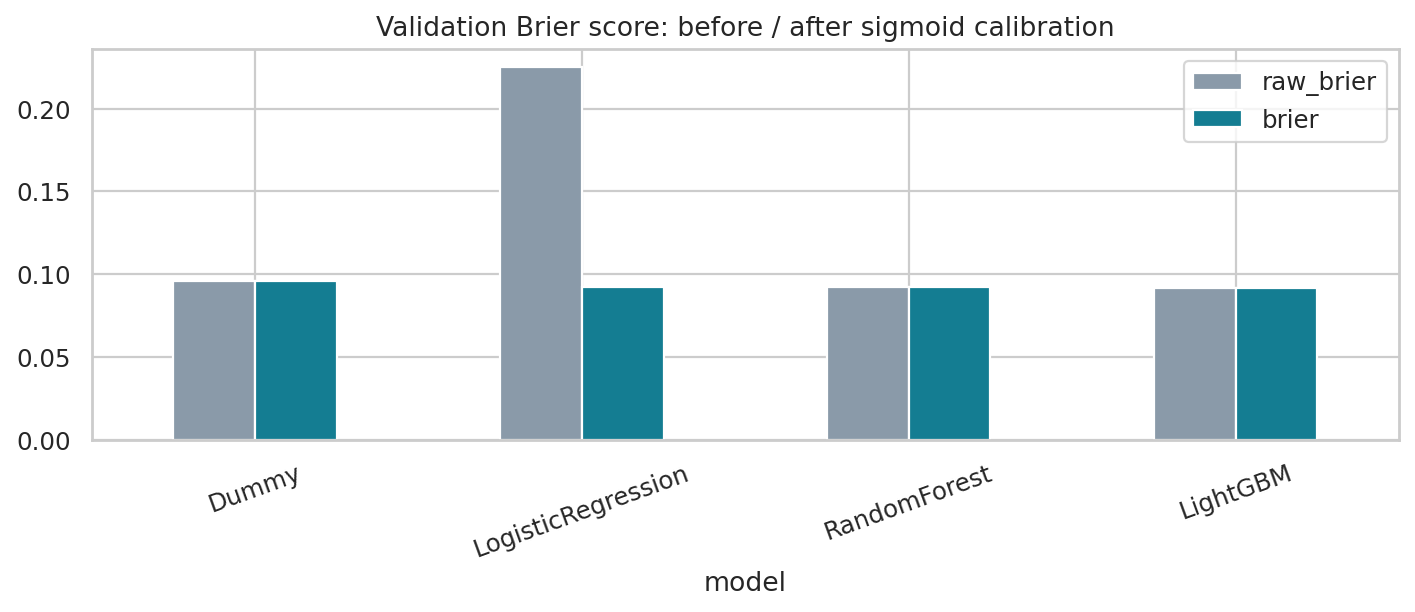

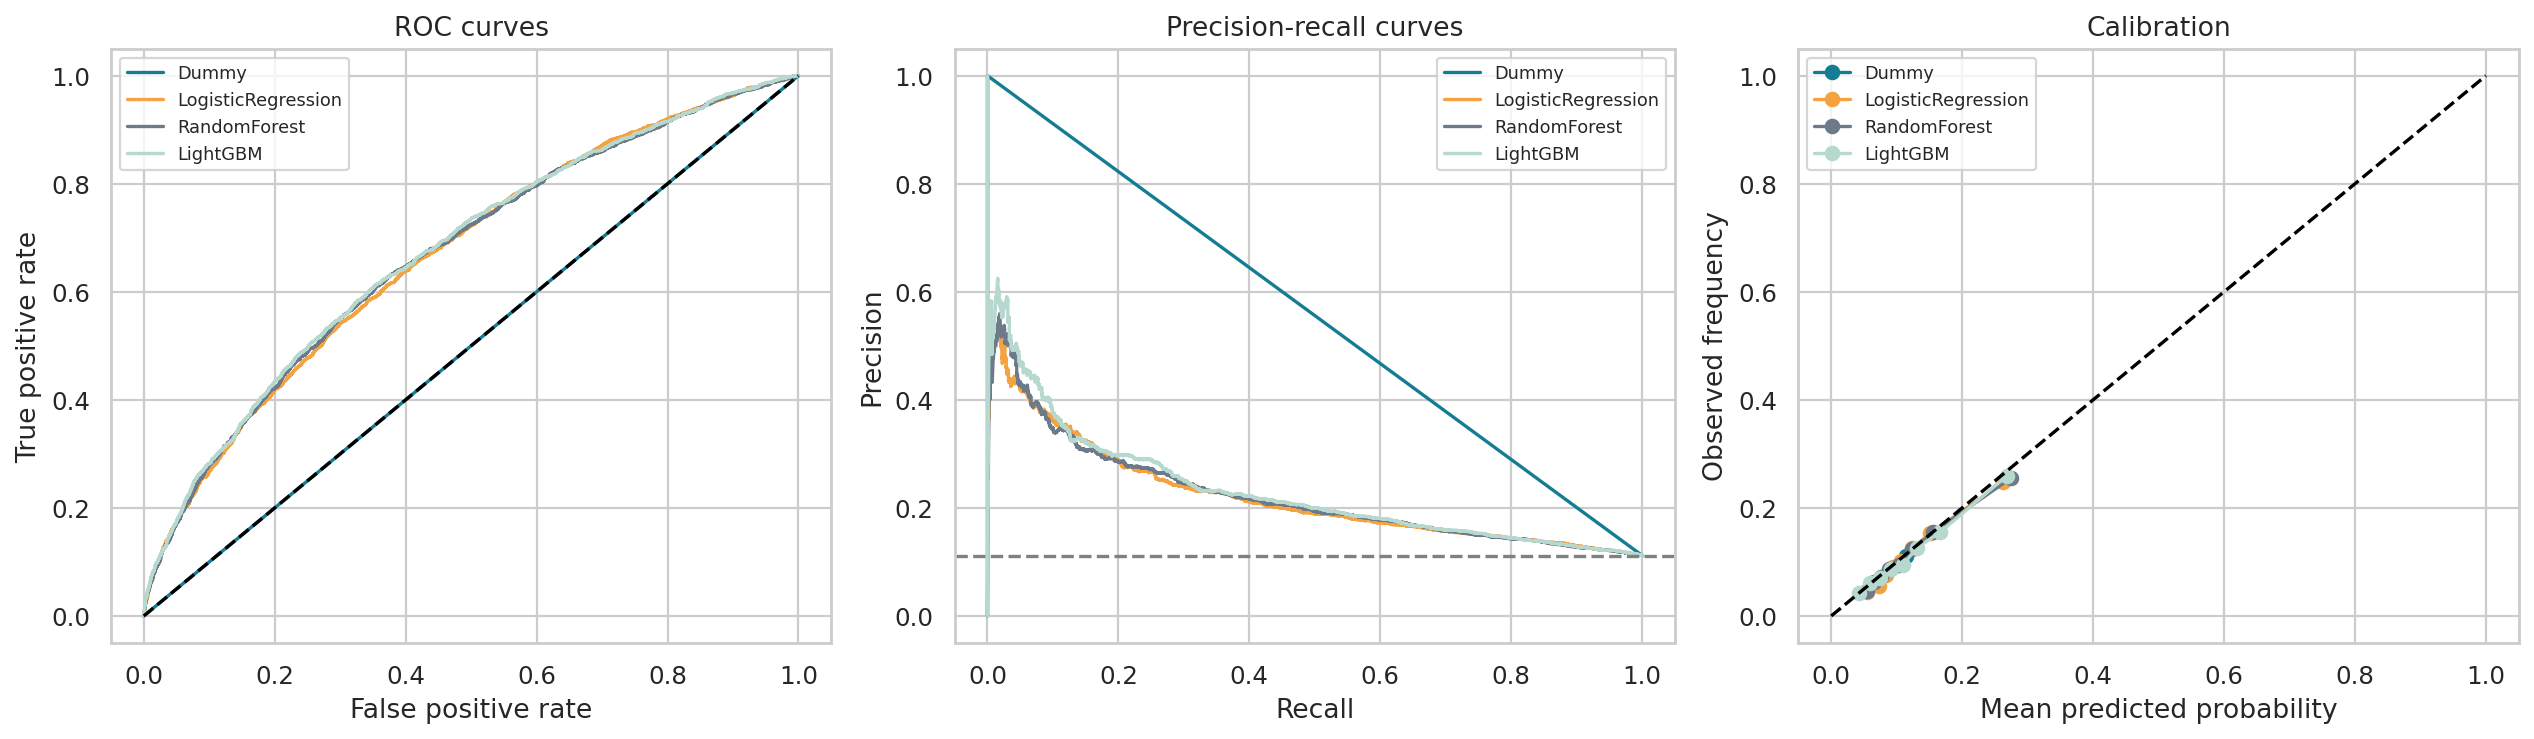

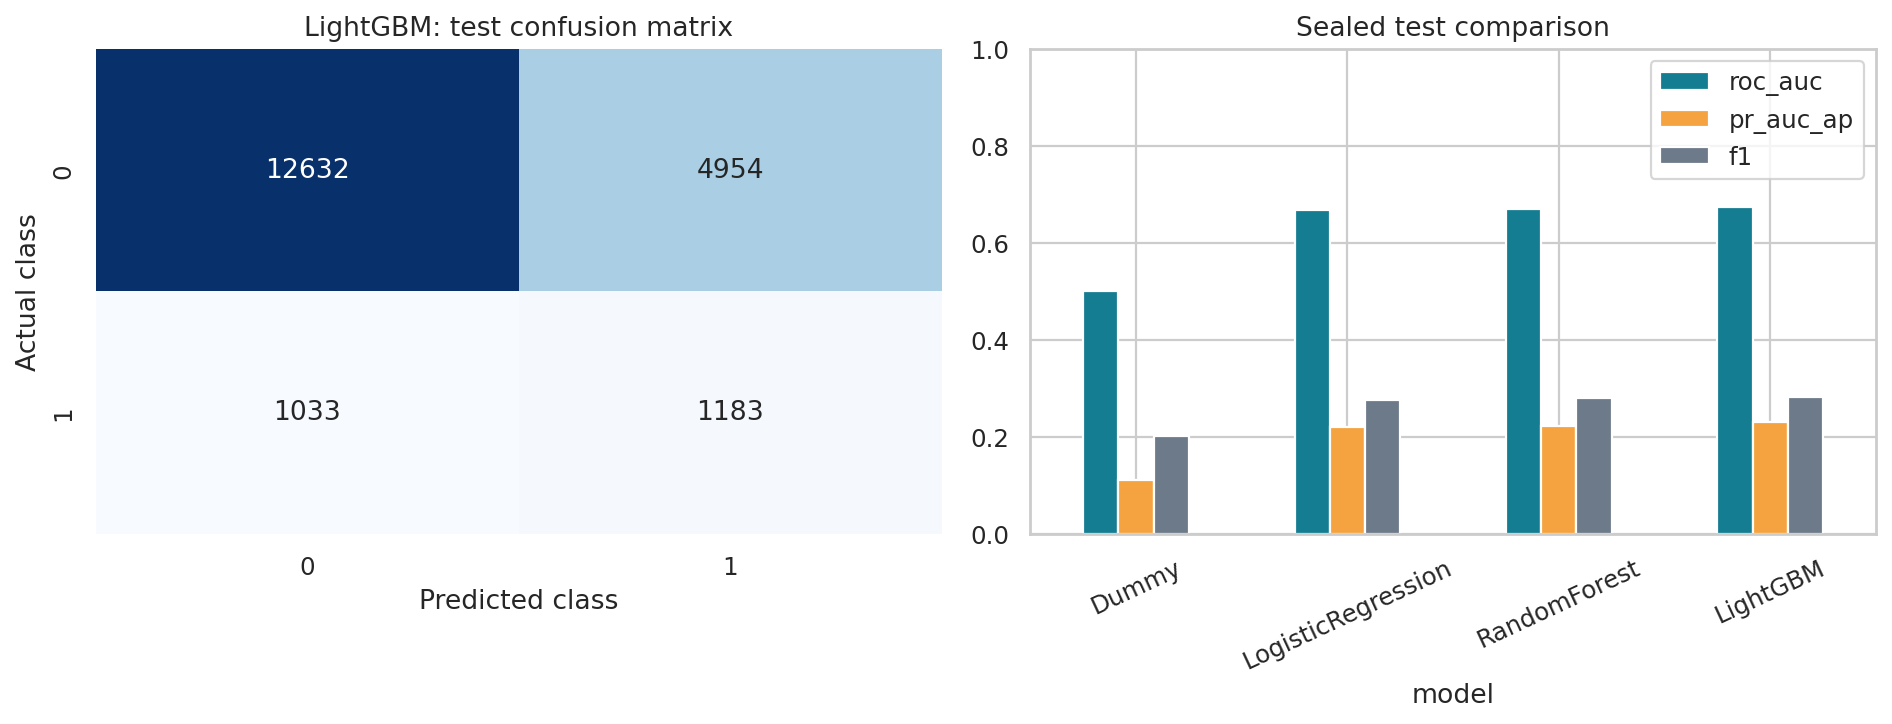

In [3]:
figure('calibration_comparison.png')
figure('model_curves.png')
figure('model_comparison.png')

## Интерпретация и ошибки
Permutation importance измерена на validation. Низкая важность отдельного признака при наличии коррелированных признаков не доказывает его бесполезность. Ошибки и подгруппы test исследуются описательно, без повторного выбора модели.

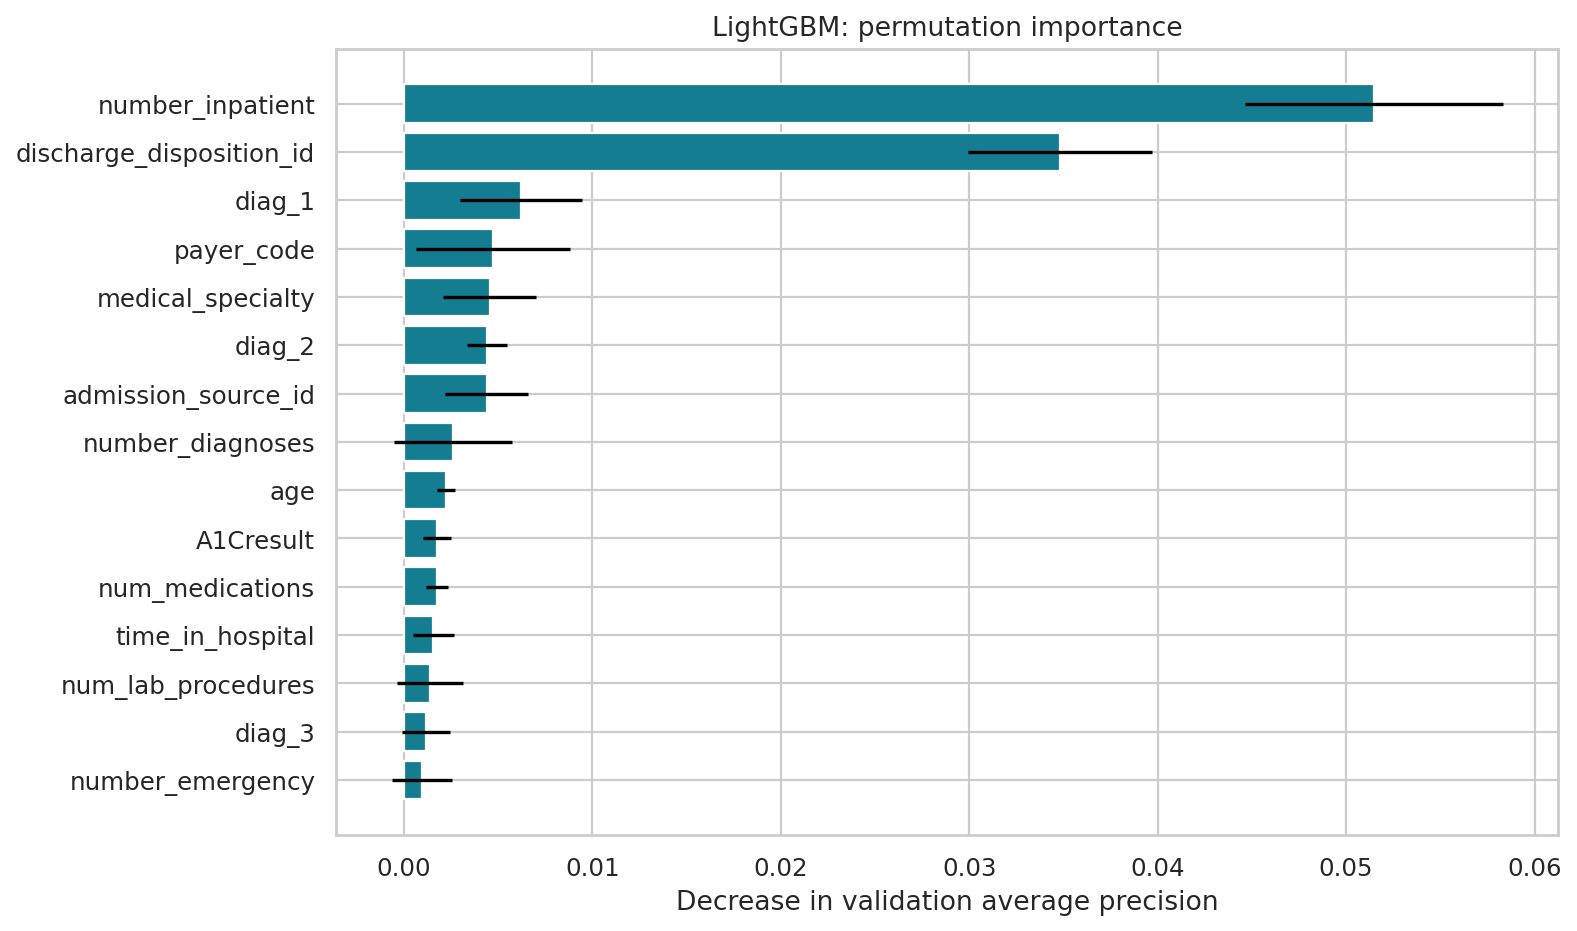

,feature,importance_mean,importance_std
0,number_inpatient,0.0515,0.0068
1,discharge_disposition_id,0.0348,0.0049
2,diag_1,0.0062,0.0032
3,payer_code,0.0047,0.0041
4,medical_specialty,0.0046,0.0025
5,diag_2,0.0044,0.0011
6,admission_source_id,0.0044,0.0022
7,number_diagnoses,0.0026,0.0031
8,age,0.0022,0.0005
9,A1Cresult,0.0018,0.0007


,error_type,encounters,patients,mean_prior_inpatient,median_prior_inpatient,mean_stay,mean_probability
0,FN,1033,995,0.199419,0.0,4.352372,0.087917
1,FP,4954,3579,1.550262,1.0,5.208115,0.194433
2,TN,12632,11207,0.159991,0.0,3.984801,0.079430
3,TP,1183,866,2.150465,1.0,5.168216,0.233529


,feature,group,n,patients,positives,observed_rate,recall,precision,f1,brier,roc_auc,interpretation
0,age,[0-10),29,28,1,0.0345,0.0000,0.0000,0.0000,0.0342,0.3214,small group: descriptive only
1,age,[10-20),138,110,9,0.0652,0.3333,0.2308,0.2727,0.0587,0.5891,small group: descriptive only
2,age,[20-30),388,250,60,0.1546,0.8833,0.3510,0.5024,0.0962,0.8656,descriptive; no causal interpretation
3,age,[30-40),729,543,77,0.1056,0.5714,0.2280,0.3259,0.0862,0.7234,descriptive; no causal interpretation
4,age,[40-50),1909,1380,202,0.1058,0.4604,0.2062,0.2848,0.0909,0.6713,descriptive; no causal interpretation
5,age,[50-60),3469,2553,356,0.1026,0.4803,0.2209,0.3027,0.0857,0.7077,descriptive; no causal interpretation
6,age,[60-70),4266,3145,464,0.1088,0.4763,0.1882,0.2698,0.0930,0.6559,descriptive; no causal interpretation
7,age,[70-80),5040,3599,587,0.1165,0.5826,0.1854,0.2812,0.0989,0.6622,descriptive; no causal interpretation
8,age,[80-90),3287,2311,390,0.1186,0.5821,0.1683,0.2611,0.1011,0.6386,descriptive; no causal interpretation
9,age,[90-100),547,378,70,0.1280,0.4143,0.1551,0.2257,0.1113,0.5334,descriptive; no causal interpretation


In [4]:
figure('permutation_importance.png')
display(table('permutation_importance.csv').round(4))
display(table('error_profiles.csv'))
display(table('subgroup_metrics.csv').round(4))

## Предсказание из сохранённого joblib
Пример содержит статистические значения по умолчанию с fit, а не сведения конкретного человека. Все поля можно изменить в JSON или Streamlit.

In [5]:
from src.inference import predict_record
record=json.loads((ROOT/'examples'/'patient.json').read_text(encoding='utf-8'))
display(pd.Series(predict_record(record)).to_frame('value'))

,value
model,LightGBM
probability,0.087111
threshold,0.13167
prediction,0
defaults_used_for,[]
unseen_categories,[]
scope,"Educational estimate at discharge, not a medic..."


## Что означают интервалы
95% интервалы получены bootstrap по пациентам. Они отражают неопределённость на данном test при фиксированной модели, не учитывают весь процесс подбора и не доказывают переносимость на современные больницы.